[INFO] BaseAviary.__init__() loaded parameters from the drone's .urdf:
[INFO] m 0.027000, L 0.039700,
[INFO] ixx 0.000014, iyy 0.000014, izz 0.000022,
[INFO] kf 3.160000e-10, km 7.940000e-12,
[INFO] t2w 2.250000, max_speed_kmh 30.000000,
[INFO] gnd_eff_coeff 11.368590, prop_radius 0.023135,
[INFO] drag_xy_coeff 0.000001, drag_z_coeff 0.000001,
[INFO] dw_coeff_1 2267.180000, dw_coeff_2 0.160000, dw_coeff_3 -0.110000
viewMatrix (0.9396926760673523, 0.0, 0.3420201241970062, 0.0, 0.3420201241970062, 0.0, -0.9396926760673523, 0.0, -0.0, 1.0000001192092896, -0.0, 0.0, -0.0, -0.0, -13.000000953674316, 1.0)
projectionMatrix (0.7499999403953552, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, -1.0000200271606445, -1.0, 0.0, 0.0, -0.02000020071864128, 0.0)


error: Not connected to physics server.

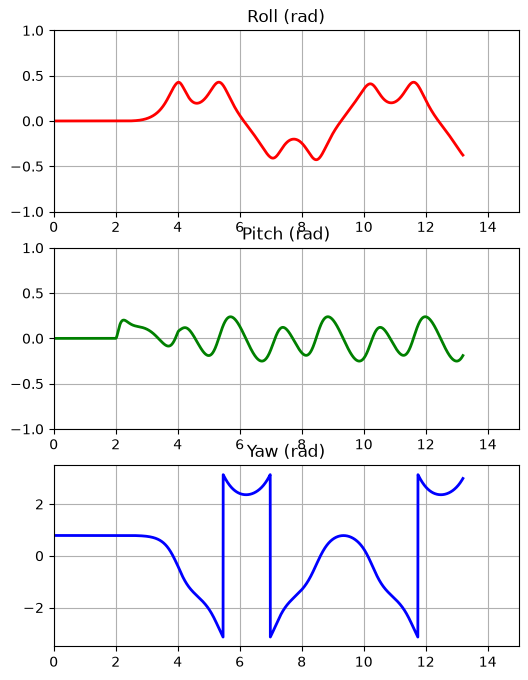

In [3]:
import time
import math
import numpy as np
import pybullet as p
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
from gym_pybullet_drones.envs.CtrlAviary import CtrlAviary
from gym_pybullet_drones.control.DSLPIDControl import DSLPIDControl


class PaperQuaternionController(DSLPIDControl):
    """
    Implements the cascaded Quaternion Attitude Control System from Golabek et al. (2022):
      - Outer Guidance System (Position PD + Accel Feedforward -> Setpoint Quaternion q_sp)
      - External Attitude Loop: Q_P Attitude Controller (Eq. 10, 17-19, 27) + Saturation
      - Internal Rate Loop: 3-axis Angular Rate PI-D Controllers
    """
    def __init__(self, drone_model):
        super().__init__(drone_model=drone_model)
        
        # 1. Outer Loop Q_P Attitude Controller Parameters (Eq. 27 & Figure 1)
        # w_sp = 2 * Kp * q_err_short
        self.KP_QUAT = 12.0             # Increased from 8.5 for faster attitude response
        self.MAX_RATE_SP = 10.0        # Saturation block limit after Q_P controller [rad/s]
        
        # 2. Inner Loop 3-Axis Angular Rate PI-D Gains (matched to Crazyflie 2.x PWM mixer)
        self.KP_RATE = np.array([4500.0, 4500.0, 3500.0])
        self.KI_RATE = np.array([250.0,  250.0,  150.0])
        self.KD_RATE = np.array([15.0,   15.0,   0.0])
        
        # Internal states for the Rate PI-D loop
        self.rate_integral = np.zeros(3)
        self.prev_omega_meas = np.zeros(3)
        self.d_omega_filt = np.zeros(3)
        self.first_step = True

    @staticmethod
    def quat_multiply(q1, q2):
        """
        Hamilton product (q1 * q2) for quaternions in [qw, qx, qy, qz] scalar-first format (Eq. 8).
        """
        w1, x1, y1, z1 = q1
        w2, x2, y2, z2 = q2
        return np.array([
            w1*w2 - x1*x2 - y1*y2 - z1*z2,
            w1*x2 + x1*w2 + y1*z2 - z1*y2,
            w1*y2 - x1*z2 + y1*w2 + z1*x2,
            w1*z2 + x1*y2 - y1*x2 + z1*w2
        ])

    @staticmethod
    def quat_conjugate(q):
        """
        Unit quaternion inverse/conjugate in [qw, qx, qy, qz] format (Eq. 7).
        """
        return np.array([q[0], -q[1], -q[2], -q[3]])

    def computeControlFromState(self, control_timestep, state, target_pos, target_vel, target_acc, target_yaw):
        cur_pos = state[0:3]
        cur_quat_xyzw = state[3:7]      # PyBullet format: [qx, qy, qz, qw]
        cur_vel = state[10:13]
        cur_ang_vel_world = state[13:16]

        # =====================================================================
        # 1. GUIDANCE SYSTEM (GS): Compute Thrust & Setpoint Quaternion (q_sp)
        # =====================================================================
        pos_e = target_pos - cur_pos
        vel_e = target_vel - cur_vel

        # Integral position error (from DSLPIDControl) with anti-windup
        self.integral_pos_e = self.integral_pos_e + pos_e * control_timestep
        self.integral_pos_e = np.clip(self.integral_pos_e, -2.0, 2.0)
        self.integral_pos_e[2] = np.clip(self.integral_pos_e[2], -0.15, 0.15)

        # Desired 3D physical acceleration vector (m/s^2), converted to Force (N) via mass
        # Note: self.GRAVITY in gym-pybullet-drones is already (m * g) in Newtons!
        mass = self.GRAVITY / 9.8
        target_force = (
            mass * (
                self.P_COEFF_FOR * pos_e
                + self.I_COEFF_FOR * self.integral_pos_e
                + self.D_COEFF_FOR * vel_e
                + target_acc
            )
            + np.array([0.0, 0.0, self.GRAVITY])
        )

        # Project total force onto current body Z-axis to get collective motor PWM thrust
        R_meas = R.from_quat(cur_quat_xyzw).as_matrix()
        scalar_thrust = max(0.0, np.dot(target_force, R_meas[:, 2]))
        thrust = (math.sqrt(scalar_thrust / (4.0 * self.KF)) - self.PWM2RPM_CONST) / self.PWM2RPM_SCALE

        # Construct the desired 3D orthonormal basis (R_sp) directly from target_force & target_yaw
        z_body_des = target_force / np.linalg.norm(target_force)
        x_c_des = np.array([math.cos(target_yaw), math.sin(target_yaw), 0.0])
        y_body_des = np.cross(z_body_des, x_c_des)
        y_body_des /= np.linalg.norm(y_body_des)
        x_body_des = np.cross(y_body_des, z_body_des)

        R_sp = np.column_stack((x_body_des, y_body_des, z_body_des))
        q_sp_xyzw = R.from_matrix(R_sp).as_quat()

        # Convert both q_sp and q_meas to the paper's [qw, qx, qy, qz] scalar-first convention
        q_sp = np.array([q_sp_xyzw[3], q_sp_xyzw[0], q_sp_xyzw[1], q_sp_xyzw[2]])
        q_meas = np.array([cur_quat_xyzw[3], cur_quat_xyzw[0], cur_quat_xyzw[1], cur_quat_xyzw[2]])

        q_sp /= np.linalg.norm(q_sp)
        q_meas /= np.linalg.norm(q_meas)

        # =====================================================================
        # 2. Q_P ATTITUDE CONTROLLER (Equations 11, 17-19, 27)
        # =====================================================================
        # Attitude Error in body coordinates (Eq. 11): q_err = q_meas^* (x) q_sp
        q_err = self.quat_multiply(self.quat_conjugate(q_meas), q_sp)

        # Shorter rotation check (Equations 17 - 19):
        if q_err[0] < 0.0:
            q_err_short = -q_err
        else:
            q_err_short = q_err

        # Equation (27): [wx_sp, wy_sp, wz_sp]^T = 2 * Kp * [qx_err_short, qy_err_short, qz_err_short]^T
        omega_sp = 2.0 * self.KP_QUAT * q_err_short[1:4]

        # Saturation block between outer Q_P loop and inner Rate loop (Figure 1)
        omega_sp = np.clip(omega_sp, -self.MAX_RATE_SP, self.MAX_RATE_SP)

        # =====================================================================
        # 3. INNER ANGULAR RATE PI-D CONTROLLERS (Section 2 & Figure 1)
        # =====================================================================
        # Transform world-frame angular velocity into aircraft body axes (wx_meas, wy_meas, wz_meas)
        omega_meas = R_meas.T @ cur_ang_vel_world

        # Angular rate error: e_omega = omega_sp - omega_meas
        omega_err = omega_sp - omega_meas

        # Integral term (with anti-windup clamping)
        self.rate_integral += omega_err * control_timestep
        self.rate_integral = np.clip(self.rate_integral, -0.5, 0.5)

        # Low-pass filtered derivative on measurement (-d(omega_meas)/dt) to prevent noise wobble
        if self.first_step:
            self.d_omega_filt = np.zeros(3)
            self.first_step = False
        else:
            raw_d_omega = (omega_meas - self.prev_omega_meas) / control_timestep
            self.d_omega_filt = 0.2 * raw_d_omega + 0.8 * self.d_omega_filt
        self.prev_omega_meas = omega_meas.copy()

        # PI-D Control Law: PI on error, D on measured feedback
        target_torques = (
            self.KP_RATE * omega_err
            + self.KI_RATE * self.rate_integral
            - self.KD_RATE * self.d_omega_filt
        )
        target_torques = np.clip(target_torques, -3200.0, 3200.0)

        # Mix collective thrust and 3-axis body torques into the 4 motor RPMs
        pwm = thrust + np.dot(self.MIXER_MATRIX, target_torques)
        pwm = np.clip(pwm, self.MIN_PWM, self.MAX_PWM)
        rpm = self.PWM2RPM_SCALE * pwm + self.PWM2RPM_CONST

        return rpm, pos_e, q_err_short


# =====================================================================
# MAIN SIMULATION (FIGURE-8 PATH, INDICATORS & TELEMETRY)
# =====================================================================
INIT_XYZ = np.array([[0.0, 0.0, 1.5]])
INIT_RPY = np.array([[0.0, 0.0, math.pi/4]])

env = CtrlAviary(gui=True, record=False, initial_xyzs=INIT_XYZ, initial_rpys=INIT_RPY)
ctrl = PaperQuaternionController(drone_model=env.DRONE_MODEL)

# Outer Position Loop Gains (in m/s^2 per meter/m/s of error)
ctrl.P_COEFF_FOR = np.array([8.0, 8.0, 10.0])   # Increased stiffness to pull directly to the red line
ctrl.I_COEFF_FOR = np.array([1.5, 1.5, 2.0])    # Increased to correct sustained curve offset
ctrl.D_COEFF_FOR = np.array([5.5, 5.5, 6.0])

obs, info = env.reset()
client = env.CLIENT
SPEED = 1.0  

# --- PRE-DRAW THE VISUAL MATHEMATICAL PATH ---
theta_path = np.linspace(0, 2*math.pi, 200)
path_x = 2.0 * np.sin(theta_path)
path_y = 2.0 * np.sin(theta_path) * np.cos(theta_path)
path_z = np.full_like(theta_path, 1.5)

for i in range(len(theta_path) - 1):
    p.addUserDebugLine(
        [path_x[i], path_y[i], path_z[i]], 
        [path_x[i+1], path_y[i+1], path_z[i+1]], 
        [1, 0, 0], 2.0, 0, physicsClientId=client
    )

# 2. Setup Live Telemetry Dashboard
plt.ion() 
fig, (ax_roll, ax_pitch, ax_yaw) = plt.subplots(3, 1, figsize=(6, 8))
fig.canvas.manager.set_window_title('Live Flight Telemetry (Quaternion Q_P + Rate PI-D)')

for ax, title in zip([ax_roll, ax_pitch, ax_yaw], ['Roll (rad)', 'Pitch (rad)', 'Yaw (rad)']):
    ax.set_title(title)
    ax.set_xlim(0, 15) 
    ax.set_ylim(-1.0, 1.0)
    ax.grid(True)
ax_yaw.set_ylim(-3.5, 3.5) 

line_roll, = ax_roll.plot([], [], 'r-', lw=2)
line_pitch, = ax_pitch.plot([], [], 'g-', lw=2)
line_yaw, = ax_yaw.plot([], [], 'b-', lw=2)

fig.canvas.draw()
fig.canvas.flush_events()

time_data, roll_data, pitch_data, yaw_data = [], [], [], []
prev_actual_pos = obs[0][0:3]

# 3. Simulation Loop
for i in range(3600):
    t = i * env.CTRL_TIMESTEP
    current_state = obs[0]
    current_pos = current_state[0:3]
    current_rpy = current_state[7:10] 
    
    # --- KINEMATIC PROFILING: Smooth Acceleration Ramp ---
    if t < 2.0:
        theta = 0.0
        theta_dot = 0.0
        theta_ddot = 0.0
    elif t >= 2.0 and t < 4.0:
        theta_ddot = SPEED / 2.0
        theta_dot = theta_ddot * (t - 2.0)
        theta = 0.5 * theta_ddot * (t - 2.0)**2
    else:
        theta_ddot = 0.0
        theta_dot = SPEED
        theta = SPEED + SPEED * (t - 4.0)

    # 1. Exact Position: x = 2*sin(theta), y = sin(2*theta)
    x = 2.0 * math.sin(theta)
    y = 2.0 * math.sin(theta) * math.cos(theta)
    target_pos = np.array([x, y, 1.5])
    
    # 2. Exact Velocity Feedforward (1st Derivative)
    vx = 2.0 * math.cos(theta) * theta_dot
    vy = 2.0 * math.cos(2.0 * theta) * theta_dot
    target_vel = np.array([vx, vy, 0.0])

    # 3. Exact Acceleration Feedforward (2nd Derivative via Chain + Product Rule)
    ax_ff = -2.0 * math.sin(theta) * (theta_dot**2) + 2.0 * math.cos(theta) * theta_ddot
    ay_ff = -4.0 * math.sin(2.0 * theta) * (theta_dot**2) + 2.0 * math.cos(2.0 * theta) * theta_ddot
    target_acc = np.array([ax_ff, ay_ff, 0.0])
    
    # 4. Exact Yaw Alignment
    if vx == 0 and vy == 0:
        target_yaw = math.pi / 4
    else:
        target_yaw = math.atan2(vy, vx)

    # Telemetry logging
    time_data.append(t)
    roll_data.append(current_rpy[0])
    pitch_data.append(current_rpy[1])
    yaw_data.append(current_rpy[2])

    p.addUserDebugLine(prev_actual_pos, current_pos, [0, 0, 1], 2.0, 0, physicsClientId=client)
    prev_actual_pos = current_pos

    if i % 48 == 0:
        line_roll.set_data(time_data, roll_data)
        line_pitch.set_data(time_data, pitch_data)
        line_yaw.set_data(time_data, yaw_data)
        fig.canvas.draw_idle()
        fig.canvas.flush_events()

    # --- QUATERNION CONTROL & PHYSICS STEP ---
    action, pos_error, quat_error = ctrl.computeControlFromState(
        control_timestep=env.CTRL_TIMESTEP, 
        state=current_state, 
        target_pos=target_pos,
        target_vel=target_vel,
        target_acc=target_acc,
        target_yaw=target_yaw
    )
    obs, reward, terminated, truncated, info = env.step(np.array([action]))
    time.sleep(env.CTRL_TIMESTEP)

plt.ioff()
plt.show()
env.close()